In [1]:
from pathlib import Path
import os
import pandas as pd
from dataclasses import dataclass
from datetime import datetime
import numpy as np
from pydantic import BaseModel
import sys

sys.path.append("..")
import scipy.signal as si
from copy import deepcopy
import json
from classes.sample.raw_data import INCFile, LMSFile
from librosa import lpc
from scipy.signal import butter, filtfilt

In [2]:
path = Path(
    os.getenv("RAW_DATA_PATH", "data/raw")
)
folders = os.listdir(path)

In [3]:
class Record(BaseModel):
    sampled_at: datetime
    cable: str
    axis: str
    tension: float
    rms: float
    error_rms: float
    frequencies: list[float]
    reals: list[float]
    imags: list[float]

In [4]:
from scipy.signal import tf2zpk, lfilter

In [5]:
def is_pole_relevant(pole: complex, all_poles: np.ndarray, fs: float) -> bool:
    # corresponding frequency point
    w = np.angle(pole)
    fi = (w * fs) / (2 * np.pi)
    pi = np.cos(2*np.pi*fi/fs) + 1j*np.sin(2*np.pi*fi/fs)

    # distances
    pole_dist = np.abs(pole - pi)
    min_dist = np.min(np.abs(all_poles - pi))

    return pole_dist == min_dist


In [6]:
def get_filter(
    fs: float, f_start: float, f_end: float, order: int
) -> tuple[list[float], list[float]]:
    if f_start == 0:
        filt = butter(N=order, Wn=f_end, fs=fs, btype="lowpass")
    elif f_end == fs/2:
        filt = butter(N=order, Wn=f_start, fs=fs, btype="highpass")
    else:
        filt = butter(
            N=order,
            Wn=[f_start, f_end],
            fs=fs,
            btype="band",
        )
    return filt
    # return {k: get_rms(filtfilt(*filt, signal)) for k, filt in filters.items()}

In [7]:
def get_features_from_lms(lms: LMSFile, order: int) -> list[Record]:
    def get_rms(x: np.ndarray) -> float:
        return np.sqrt(np.mean(np.square(x)))
    
    sampled_at = lms.sampled_at
    dt = lms.dt
    fs = 1 / dt
    b, a = get_filter(fs=fs, f_start=0, f_end=30, order=10)
    records = []
    for cable in ["c1", "c2", "c3", "c4"]:
        tension = np.mean(getattr(lms, f"s{cable[-1]}"))
        for ax in ["x", "y", "z"]:
            raw_signal = np.array(getattr(lms, f"{cable}_{ax}"))
            signal = filtfilt(b=b, a=a, x=raw_signal)
            rms = get_rms(signal)
            
            # lpc
            a_lpc = lpc(signal, order=order)
            zeros, _, _ = tf2zpk(a=1, b=a_lpc)
            is_relevant = [is_pole_relevant(z, zeros, fs) for z in zeros]
            w = np.angle(zeros)
            freq_zeros_hz = (w * fs) / (2 * np.pi)
            relevant_poles = zeros[is_relevant]
            relevant_freqs = freq_zeros_hz[is_relevant]
            relevant_poles = [p for r, p in zip(relevant_freqs, relevant_poles) if r>0]
            relevant_freqs = [r for r in relevant_freqs if r>0]
            reals = [float(np.real(r)) for r in relevant_poles]
            imags = [float(np.imag(r)) for r in relevant_poles]

            # error rms
            e = lfilter(b=a_lpc, a=1, x=np.array(signal))
            error_rms = np.sqrt(np.mean(np.square(e)))
    
            record = Record(
                sampled_at=sampled_at,
                cable=cable,
                axis=ax,
                tension=tension,
                rms=rms,
                error_rms=error_rms,
                frequencies=relevant_freqs,
                reals=reals,
                imags=imags
            )
            records.append(record.dict())
    return records

In [8]:
records = []
count = 0
processed_docs = []

for folder in folders:
    if not folder.startswith("Teste"):
        continue
    files = os.listdir(path / folder)
    prefixes = [f[:-8] for f in files if f.endswith(".txt")]
    prefixes = np.unique(prefixes)
    for prefix in prefixes:
        if prefix in processed_docs:
            continue
        processed_docs.append(prefix)
        lms_path = path / folder / f"{prefix}_LMS.txt"
        try:
            lms_file = LMSFile.from_txt(lms_path)
        except:
            continue
        rec = get_features_from_lms(lms_file, order=10)
        records += rec
        count += 1

In [9]:
records_df = pd.DataFrame(records)
output_path = Path("../data/features")
records_df.to_csv(output_path / "features_lpc_filtered_seq1.csv")

# view

In [10]:
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

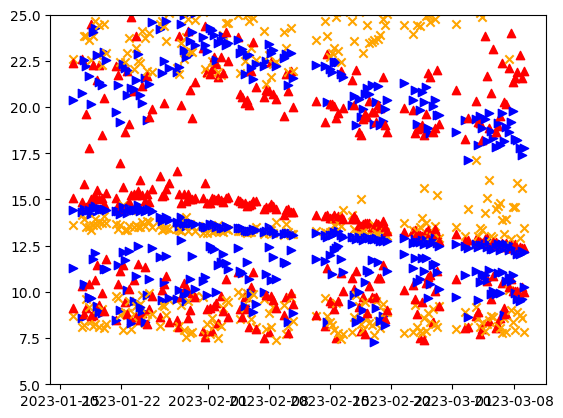

In [17]:
df = records_df.loc[(records_df["cable"]=="c3")]

fig = plt.figure()
ax = fig.add_subplot()

config = {
    "x": {"color": "orange", "marker": "x"},
    "y": {"color": "red", "marker": "^"},
    "z": {"color": "blue", "marker": ">"},
}

last_date_per_axis = {
    "x": datetime(1950,1,1),
    "y": datetime(1950,1,1),
    "z": datetime(1950,1,1)
}

for k, row in df.iterrows():
    freqs = row["frequencies"]
    date = row["sampled_at"]
    axis = row["axis"]
    if date < datetime(2023, 1, 10):
        continue
    if date - last_date_per_axis[axis] < timedelta(hours=6):
        continue
    for f in freqs:
        ax.scatter(date, f, color=config[axis]["color"], marker=config[axis]["marker"])
        last_date_per_axis[axis] = date
    plt.ylim([5, 25])